# U.S. Inflation and Natural Resource Prices Analysis

I wanted to see how changes in crude oil and natural gas prices are related to U.S. inflation.

**Data:** Two Kaggle datasets, cleaned in `notebooks/01_clean_data.ipynb`  
**Period:** January 2008 – July 2021  
**Tools:** Pandas and Matplotlib

This notebook starts with the cleaned monthly data and focuses on the analysis and graphs.

## 1. Load the cleaned dataset

The raw files were cleaned and combined in `notebooks/01_clean_data.ipynb`. I loaded the processed CSV to look at the relationship between inflation and resource prices.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if not (ROOT / "data").exists():
    ROOT = ROOT.parent
DATA = ROOT / "data" / "processed" / "inflation_resource_monthly.csv"
FIGURES = ROOT / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(DATA, parse_dates=["Date"])
df = df.set_index("Date").sort_index()

display(df.head())

,CPI,Inflation_MoM_pct,Inflation_YoY_pct,WTI,Brent,Natural_Gas,WTI_Change_pct,Brent_Change_pct,Gas_Change_pct
Date,,,,,,,,,
2008-01-01,211.080,0.497058,4.280294,92.929047,92.112381,7.991476,1.293346,0.786027,11.320502
2008-02-01,211.693,0.290411,4.026555,95.348999,94.652500,8.642250,2.604085,2.757631,8.143349
2008-03-01,213.528,0.866821,3.981456,105.420000,102.798999,9.624300,10.562251,8.606745,11.363359
2008-04-01,214.823,0.606478,3.936890,112.462728,110.441817,10.288091,6.680637,7.434720,6.897031
2008-05-01,216.632,0.842089,4.175543,125.458572,124.380951,11.381619,11.555690,12.621246,10.629067


## 2. Check the data

First, I checked the number of rows, column types, missing values, and basic statistics.

In [2]:
print("Shape:", df.shape)
print("Date range:", df.index.min().date(), "to", df.index.max().date())
print("Missing values:")
print(df.isna().sum())

Shape: (163, 9)
Date range: 2008-01-01 to 2021-07-01
Missing values:
CPI                  0
Inflation_MoM_pct    0
Inflation_YoY_pct    0
WTI                  0
Brent                0
Natural_Gas          0
WTI_Change_pct       0
Brent_Change_pct     0
Gas_Change_pct       0
dtype: int64


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 163 entries, 2008-01-01 to 2021-07-01
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CPI                163 non-null    float64
 1   Inflation_MoM_pct  163 non-null    float64
 2   Inflation_YoY_pct  163 non-null    float64
 3   WTI                163 non-null    float64
 4   Brent              163 non-null    float64
 5   Natural_Gas        163 non-null    float64
 6   WTI_Change_pct     163 non-null    float64
 7   Brent_Change_pct   163 non-null    float64
 8   Gas_Change_pct     163 non-null    float64
dtypes: float64(9)
memory usage: 12.7 KB


In [4]:
df[["Inflation_MoM_pct", "Inflation_YoY_pct", "WTI", "Brent", "Natural_Gas"]].describe().round(2)

,Inflation_MoM_pct,Inflation_YoY_pct,WTI,Brent,Natural_Gas
count,163.00,163.00,163.00,163.00,163.00
mean,0.16,1.81,70.86,76.80,3.68
std,0.39,1.36,23.99,26.60,1.78
min,-1.92,-2.10,16.70,26.63,1.70
25%,-0.05,1.14,50.63,55.36,2.70
50%,0.17,1.73,67.85,71.76,3.24
75%,0.42,2.35,93.00,105.57,4.08
max,1.01,5.60,134.02,134.10,12.78


## 3. CPI inflation and oil prices over time

The CPI index measures the price level, so I used its year-over-year percentage change to show inflation. WTI and Brent are average monthly futures prices in dollars per barrel. The charts use separate panels because their units are different.

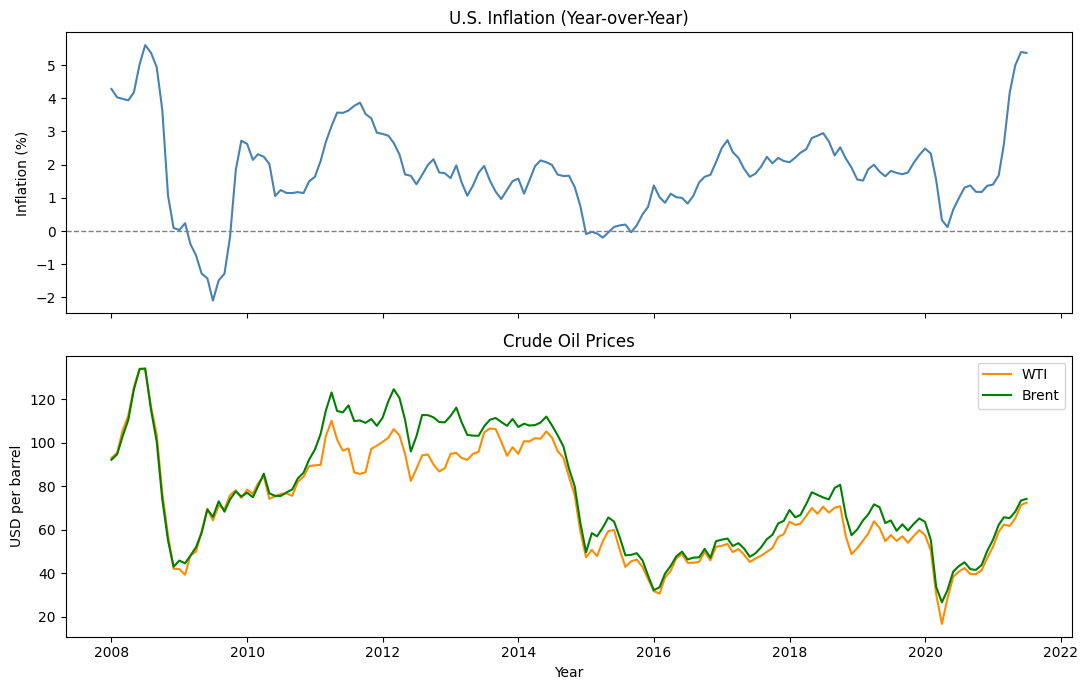

In [5]:
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)

axes[0].plot(df.index, df["Inflation_YoY_pct"], color="steelblue")
axes[0].axhline(0, color="gray", linestyle="--", linewidth=1)
axes[0].set_title("U.S. Inflation (Year-over-Year)")
axes[0].set_ylabel("Inflation (%)")

axes[1].plot(df.index, df["WTI"], label="WTI", color="darkorange")
axes[1].plot(df.index, df["Brent"], label="Brent", color="green")
axes[1].set_title("Crude Oil Prices")
axes[1].set_ylabel("USD per barrel")
axes[1].legend()
axes[1].set_xlabel("Year")

plt.tight_layout()
plt.savefig(FIGURES / "01_inflation_and_oil.png", dpi=150)
plt.show()

**What I noticed:** Oil prices fell sharply in 2008–2009 and again in 2020. Inflation also changed during these periods, but the lines do not always follow the same pattern. This graph alone cannot show that oil prices caused inflation.

## 4. Compare monthly changes

Price levels can move together over long periods even when their short-term changes are different. Here I compare monthly CPI inflation with the monthly percentage change in WTI oil prices.

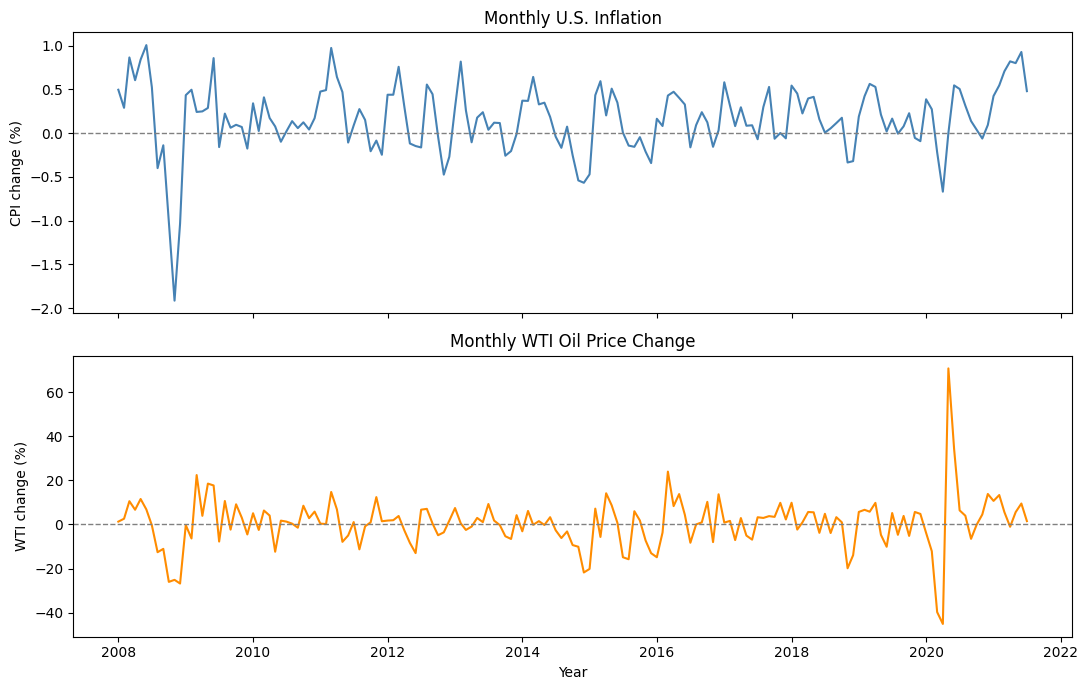

In [6]:
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)

axes[0].plot(df.index, df["Inflation_MoM_pct"], color="steelblue")
axes[0].axhline(0, color="gray", linestyle="--", linewidth=1)
axes[0].set_title("Monthly U.S. Inflation")
axes[0].set_ylabel("CPI change (%)")

axes[1].plot(df.index, df["WTI_Change_pct"], color="darkorange")
axes[1].axhline(0, color="gray", linestyle="--", linewidth=1)
axes[1].set_title("Monthly WTI Oil Price Change")
axes[1].set_ylabel("WTI change (%)")
axes[1].set_xlabel("Year")

plt.tight_layout()
plt.savefig(FIGURES / "02_monthly_changes.png", dpi=150)
plt.show()

**What I noticed:** Oil prices change much more sharply from month to month than CPI. The size of the changes is very different, even when both move up or down in the same month.

## 5. Correlation between inflation and resource prices

I used monthly percentage changes instead of comparing raw dollar prices with CPI. Correlation goes from -1 to 1. It measures how two variables move together, not whether one causes the other.

In [7]:
cols = ["Inflation_MoM_pct", "WTI_Change_pct", "Brent_Change_pct", "Gas_Change_pct"]
corr = df[cols].corr()
corr.round(2)

,Inflation_MoM_pct,WTI_Change_pct,Brent_Change_pct,Gas_Change_pct
Inflation_MoM_pct,1.00,0.52,0.63,0.10
WTI_Change_pct,0.52,1.00,0.89,0.15
Brent_Change_pct,0.63,0.89,1.00,0.17
Gas_Change_pct,0.10,0.15,0.17,1.00


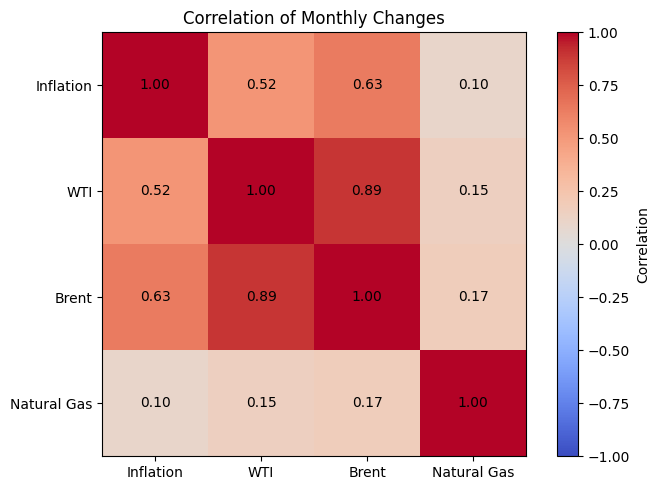

In [8]:
plt.figure(figsize=(7, 5))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Correlation")
plt.xticks(range(4), ["Inflation", "WTI", "Brent", "Natural Gas"])
plt.yticks(range(4), ["Inflation", "WTI", "Brent", "Natural Gas"])
plt.title("Correlation of Monthly Changes")

for i in range(4):
    for j in range(4):
        plt.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center")

plt.tight_layout()
plt.savefig(FIGURES / "03_correlation_heatmap.png", dpi=150)
plt.show()

**What I noticed:** In this sample, monthly inflation has a stronger positive correlation with Brent and WTI changes than with natural gas changes. This is a descriptive result, not an estimate of the effect of oil on inflation.

## 6. Scatter plots: energy price changes vs. inflation

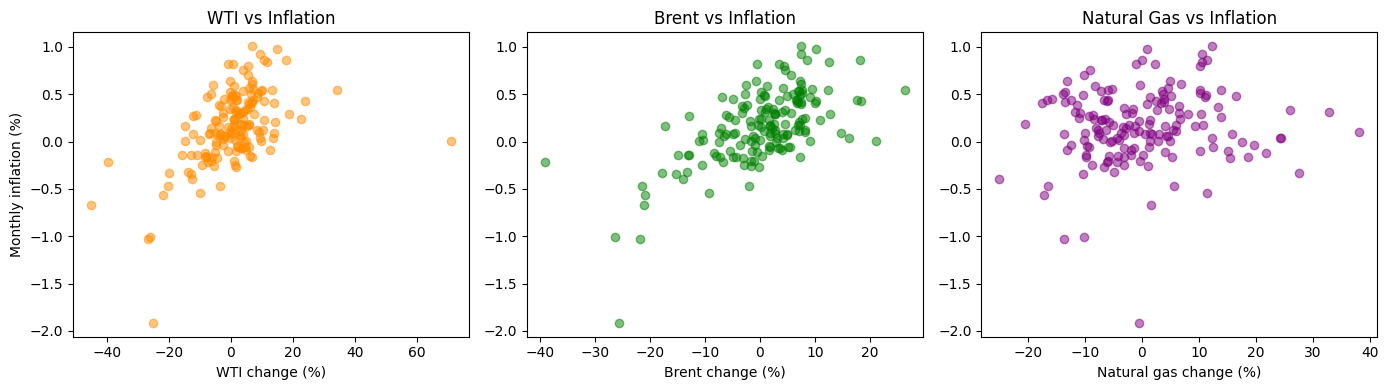

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

axes[0].scatter(df["WTI_Change_pct"], df["Inflation_MoM_pct"], alpha=0.5, color="darkorange")
axes[0].set_title("WTI vs Inflation")
axes[0].set_xlabel("WTI change (%)")
axes[0].set_ylabel("Monthly inflation (%)")

axes[1].scatter(df["Brent_Change_pct"], df["Inflation_MoM_pct"], alpha=0.5, color="green")
axes[1].set_title("Brent vs Inflation")
axes[1].set_xlabel("Brent change (%)")

axes[2].scatter(df["Gas_Change_pct"], df["Inflation_MoM_pct"], alpha=0.5, color="purple")
axes[2].set_title("Natural Gas vs Inflation")
axes[2].set_xlabel("Natural gas change (%)")

plt.tight_layout()
plt.savefig(FIGURES / "04_scatter_plots.png", dpi=150)
plt.show()

**What I noticed:** The oil scatter plots show a clearer upward pattern than natural gas. There is still a lot of variation, so oil prices alone do not explain monthly inflation.

## 7. Does the relationship change over time?

I calculated the correlation between monthly CPI inflation and WTI percentage changes over a moving 12-month window. A shorter sample can give unstable correlation values, so I use this only as an exploratory chart.

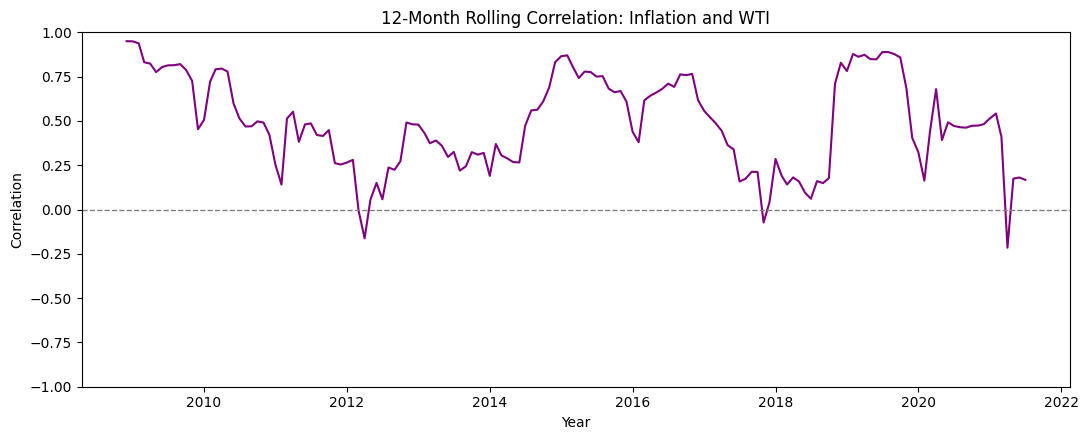

In [10]:
rolling_corr = df["Inflation_MoM_pct"].rolling(12).corr(df["WTI_Change_pct"])

plt.figure(figsize=(11, 4.5))
plt.plot(rolling_corr.index, rolling_corr, color="purple")
plt.axhline(0, color="gray", linestyle="--", linewidth=1)
plt.ylim(-1, 1)
plt.title("12-Month Rolling Correlation: Inflation and WTI")
plt.xlabel("Year")
plt.ylabel("Correlation")
plt.tight_layout()
plt.savefig(FIGURES / "05_rolling_correlation.png", dpi=150)
plt.show()

**What I noticed:** The correlation changes over time. This means the relationship in one short period should not be treated as a rule for every year.

## 8. WTI vs. Brent price difference

WTI and Brent are two different oil benchmarks. I subtracted the WTI price from the Brent price to see when the gap was larger.

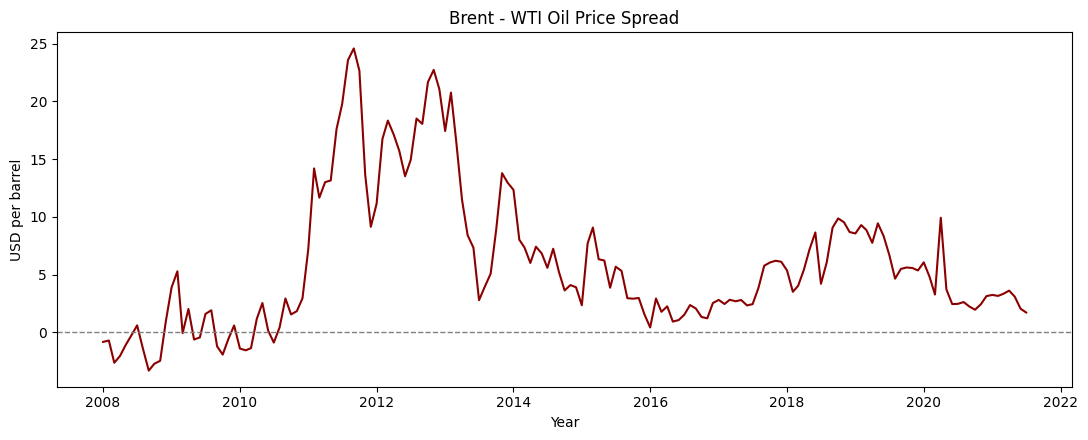

In [11]:
df_spread = df.copy()
df_spread["Brent_WTI_Spread"] = df_spread["Brent"] - df_spread["WTI"]

plt.figure(figsize=(11, 4.5))
plt.plot(df_spread.index, df_spread["Brent_WTI_Spread"], color="darkred")
plt.axhline(0, color="gray", linestyle="--", linewidth=1)
plt.title("Brent - WTI Oil Price Spread")
plt.xlabel("Year")
plt.ylabel("USD per barrel")
plt.tight_layout()
plt.savefig(FIGURES / "06_brent_wti_spread.png", dpi=150)
plt.show()

In [12]:
print("Average spread:", round(df_spread["Brent_WTI_Spread"].mean(), 2))
print("Largest spread:")
print(df_spread["Brent_WTI_Spread"].sort_values(ascending=False).head(5).round(2))

Average spread: 5.93
Largest spread:
Date
2011-09-01    24.58
2011-08-01    23.57
2012-11-01    22.73
2011-10-01    22.66
2012-10-01    21.67
Name: Brent_WTI_Spread, dtype: float64


**What I noticed:** WTI and Brent usually move together, but the difference between them was especially large in parts of 2011–2012. This is a price comparison only; finding the reason would need more data.

## 9. Compare inflation in 2019, 2020, and 2021

The CPI file stops in July 2021, so the 2021 average uses only January–July. These values are *average monthly inflation*, not annual inflation rates.

In [13]:
recent = df.loc["2019":"2021"].copy()
recent["Year"] = recent.index.year
period_avg = recent.groupby("Year")["Inflation_MoM_pct"].mean()
print(period_avg.round(3))

Year
2019    0.189
2020    0.113
2021    0.674
Name: Inflation_MoM_pct, dtype: float64


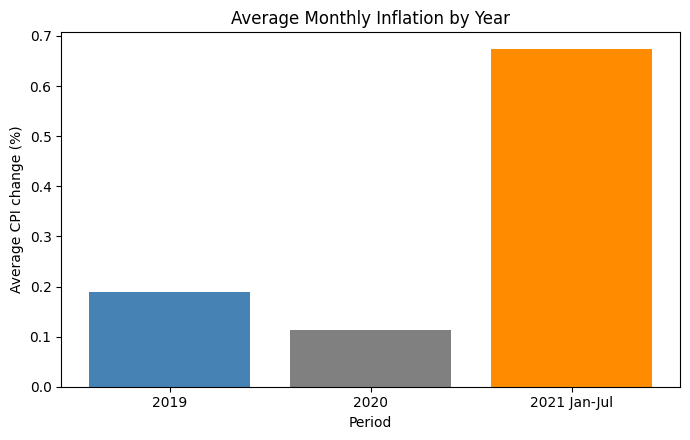

In [14]:
plt.figure(figsize=(7, 4.5))
plt.bar(["2019", "2020", "2021 Jan-Jul"], period_avg.values, color=["steelblue", "gray", "darkorange"])
plt.title("Average Monthly Inflation by Year")
plt.xlabel("Period")
plt.ylabel("Average CPI change (%)")
plt.tight_layout()
plt.savefig(FIGURES / "07_recent_inflation.png", dpi=150)
plt.show()

**What I noticed:** The average monthly CPI increase was higher in January–July 2021 than in 2019 or 2020. Because 2021 is incomplete, these periods are not exactly the same length.

## 10. Inflation distribution

A histogram makes it easier to see how often monthly inflation was positive, near zero, or negative.

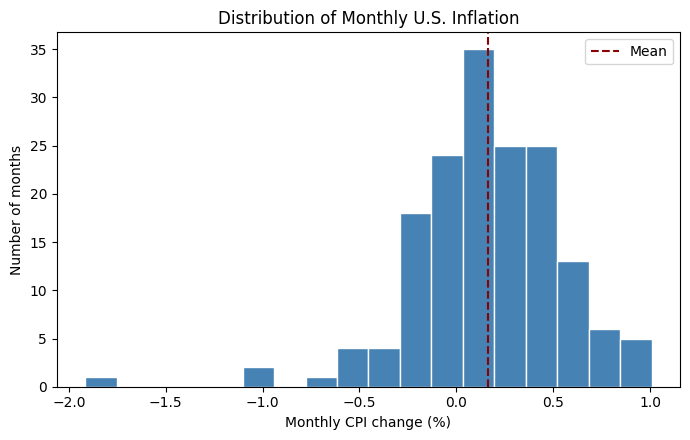

In [15]:
plt.figure(figsize=(7, 4.5))
plt.hist(df["Inflation_MoM_pct"], bins=18, color="steelblue", edgecolor="white")
plt.axvline(df["Inflation_MoM_pct"].mean(), color="darkred", linestyle="--", label="Mean")
plt.title("Distribution of Monthly U.S. Inflation")
plt.xlabel("Monthly CPI change (%)")
plt.ylabel("Number of months")
plt.legend()
plt.tight_layout()
plt.savefig(FIGURES / "08_inflation_histogram.png", dpi=150)
plt.show()

## 11. Summary

- The monthly change in WTI and Brent prices had a positive correlation with monthly U.S. inflation in this sample.
- Natural gas price changes showed a much weaker relationship with monthly inflation.
- Oil prices were more volatile than CPI, and the rolling correlation changed over time.
- Brent and WTI prices were generally close, but their price difference was not constant.

**Limitations:** This is only a comparison of two datasets. It does not prove that commodity prices caused inflation. The CPI file ends in July 2021, so this project does not cover more recent inflation. Daily futures prices were converted to monthly averages, and no forecasting model was used.